# Surrogate Model Convergence
This notebook provides a template for checking and plotting the convergence of surrogate models based on the number of points sampled randomly.
Multiple random samples are taken from each function to check method accuracy relative to number of samples.

In [131]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import multi_fidelity_functions as mfs
from SurrogateModels import kriging

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Convergence Over Different Dimensions
Test a set of functions from 1-8 dimensions for accuracy in fitting a function

In [132]:
# Set some storage ontainers
error = {}
points = {}

In [133]:
def create_test_points(func: mfs.MultiFidelityTemplate, n=2000):
    # Create a set of samples to create a ground truth
    X_test = func.sample_random(n)
    y_test = func.high_fidelity(X_test)
    return X_test, y_test


def generate_model_comparisons(
    name,
    func: mfs.MultiFidelityTemplate,
    X_test,
    y_test,
    sample_low=5,
    sample_high=105,
    step_size=5,
    seeds=5,
    model_error = {},
    points = {}
):
    # Generate a Kriging model of the data and test accuracy using a number of random sample points
    n_points = list(range(sample_low, sample_high, step_size))
    points[name] = []
    model_error[name] = []
    for seed in range(0, seeds):
        for n in n_points:
            X_train = func.sample_random(n, seed=seed)
            y_train = func.high_fidelity(X_train)
            model = kriging.Kriging(X_train, y_train, nugget=1e-7)
            model_error[name].append(model.model_error(X_test, y_test))
            points[name].append(n)

def plot_error_measure(points, error, name, color="blue", marker = "o", label = "Test",ax=None):
    if ax == None:
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    ax.scatter(
        points,
        error,
        color=color,
        label=label,
        marker=marker,
    )
    ax.set_xlabel("Samples")
    ax.set_ylabel("RMS Error")
    ax.legend()
    ax.grid()
    ax.set_yscale("log")
    return ax

In [140]:
# CHECK IF KRIGING MODEL NEEDS OPTIMIZER TUNING ON 1D CASE
key = "8D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=2000)
generate_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=10,
    sample_high=400,
    step_size=10,
    seeds=3,
    model_error=error,
    points=points,
)

C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:91: RuntimeWarning: divide by zero encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))
c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\scipy\optimize\_numdiff.py:592: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0


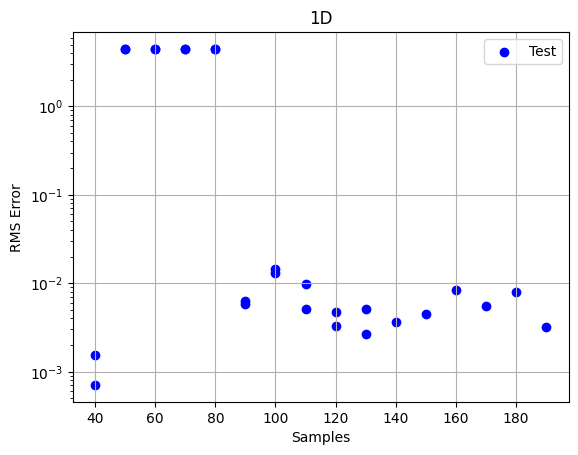

In [135]:
ax = plot_error_measure(points["1D"],error["1D"],name = "1D")


C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:32: RuntimeWarning: Method BFGS cannot handle bounds.
  result = scipy.optimize.minimize(fun, x0, method="Nelder-Mead", bounds=bounds)
C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:77: RuntimeWarning: divide by zero encountered in power
  diffs_powered = diffs ** p[np.newaxis, np.newaxis, :]
C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:91: RuntimeWarning: invalid value encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))
C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:91: RuntimeWarning: divide by zero encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))
C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:91: RuntimeWarning: invalid value encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))
C:\Users\troyz\GitPro

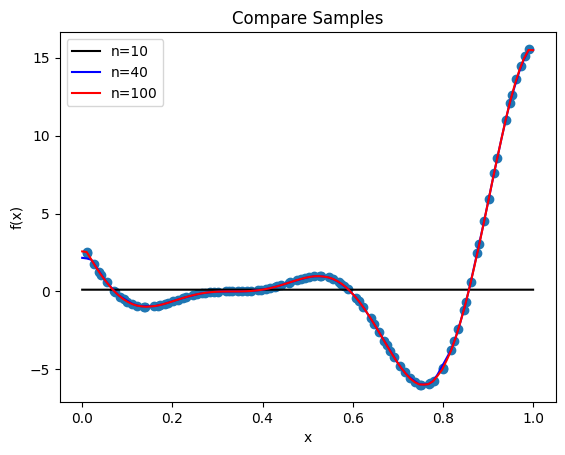

In [ ]:
X_train = my_function.sample_random(10, seed=0)
y_train = my_function.high_fidelity(X_train)
model1 = kriging.Kriging(X_train, y_train, nugget=1e-7)
X_train = my_function.sample_random(50, seed=0)
y_train = my_function.high_fidelity(X_train)
model2 = kriging.Kriging(X_train, y_train, nugget=1e-7)
X_train = my_function.sample_random(100, seed=0)
y_train = my_function.high_fidelity(X_train)
model3 = kriging.Kriging(X_train, y_train, nugget=1e-7)
ax = model1.plot_model(bounds=my_function.bounds,name="Compare Samples",color="black",label="n=10",n_samples=100)
ax = model2.plot_model(bounds=my_function.bounds,name="Compare Samples",color="blue",label="n=40",n_samples=100,ax=ax)
ax = model3.plot_model(bounds=my_function.bounds,name="Compare Samples",color="red",label="n=100",n_samples=100,ax=ax)
ax.scatter(X_train,y_train)
ax.legend()
ax.set_xlim([0.7,0.75])
plt.show()


In [ ]:
for key, value in mfs.increasing_dimensions.items():
    my_function = value()
    X_test, y_test = create_test_points(my_function, n=2000)
    generate_model_comparisons(
        key,
        my_function,
        X_test=X_test,
        y_test=y_test,
        sample_low=10,
        sample_high=500,
        step_size=10,
        seeds=5,
        model_error=error,
        points=points,
    )

    

C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:91: RuntimeWarning: divide by zero encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))
c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\scipy\optimize\_numdiff.py:592: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0
c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\numpy\linalg\linalg.py:2180: RuntimeWarning: invalid value encountered in det
  r = _umath_linalg.det(a, signature=signature)


KeyboardInterrupt: 

In [108]:
plot_error_measure(points["1D"],error["1D"],name = "1D",ax=ax,color="red",label="LBFGS")
plot_error_measure(points["2D"],error["2D"],name = "2D")
plot_error_measure(points["4D"],error["4D"],name = "4D")
plot_error_measure(points["6D"],error["6D"],name = "6D")
plot_error_measure(points["8D"],error["8D"],name = "8D")

KeyError: '2D'

In [ ]:
# Generate a Kriging model of the data and test accuracy using a number of random sample points
n_points = list(range(5, 105, 5))
points = []
model_error = []
for seed in range(1, 4):
    for n in n_points:
        X_train = my_function.sample_random(n, seed=seed)
        y_train = my_function.high_fidelity(X_train)
        model = kriging.Kriging(X_train, y_train, nugget=1e-7)
        model_error.append(model.model_error(X_test, y_test))
        points.append(n)

C:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels\kriging.py:91: RuntimeWarning: divide by zero encountered in log
  mle = -0.5 * (self.n * np.log(sigma) + np.log(np.linalg.det(psi)))
c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\scipy\optimize\_numdiff.py:592: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0


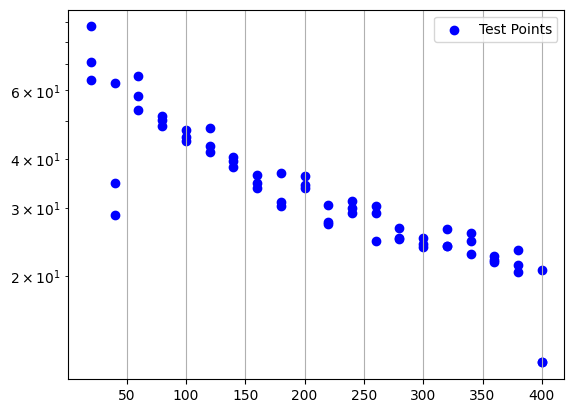

In [ ]:
# Define the function
my_function = mfs.increasing_dimensions["2D"]

# Create a set of samples to create a ground truth
# Here n = 100*dimensions is used
n = 100 * my_function.dimensions
X_test = my_function.sample_uniform(n)
y_test = my_function.high_fidelity(X_test)

In [ ]:
# Generate a Kriging model of the data and test accuracy using a number of random sample points
n_points = list(range(5, 105,5))
points = []
model_error = []
for seed in range(1, 4):
    for n in n_points:
        X_train = my_function.sample_random(n, seed=seed)
        y_train = my_function.high_fidelity(X_train)
        model = kriging.Kriging(X_train, y_train, nugget=1E-7)
        model_error.append(model.model_error(X_test, y_test))
        points.append(n)

In [ ]:
plot_name = "Accuracy Relative to Number of Points"
plt.figure(plot_name)
plt.title("")
plt.scatter(
    points,
    model_error,
    color="blue",
    label="Test Points",
    marker="o",
)
plt.legend()
plt.grid()
plt.yscale("log")
plt.show()

In [ ]:
# Define the function
my_function = mfs.increasing_dimensions["4D"]

# Create a set of samples to create a ground truth
# Here n = 100*dimensions is used
n = 100 * my_function.dimensions
X_test = my_function.sample_uniform(n)
y_test = my_function.high_fidelity(X_test)

In [ ]:
# Generate a Kriging model of the data and test accuracy using a number of random sample points
n_points = list(range(5, 105,5))
points = []
model_error = []
for seed in range(1, 4):
    for n in n_points:
        X_train = my_function.sample_random(n, seed=seed)
        y_train = my_function.high_fidelity(X_train)
        model = kriging.Kriging(X_train, y_train, nugget=1E-7)
        model_error.append(model.model_error(X_test, y_test))
        points.append(n)

In [ ]:
plot_name = "Accuracy Relative to Number of Points"
plt.figure(plot_name)
plt.title("")
plt.scatter(
    points,
    model_error,
    color="blue",
    label="Test Points",
    marker="o",
)
plt.legend()
plt.grid()
plt.yscale("log")
plt.show()

In [ ]:
# Define the function
my_function = mfs.increasing_dimensions["6D"]

# Create a set of samples to create a ground truth
# Here n = 100*dimensions is used
n = 100 * my_function.dimensions
X_test = my_function.sample_uniform(n)
y_test = my_function.high_fidelity(X_test)

In [ ]:
# Generate a Kriging model of the data and test accuracy using a number of random sample points
n_points = list(range(5, 105,5))
points = []
model_error = []
for seed in range(1, 4):
    for n in n_points:
        X_train = my_function.sample_random(n * my_function.dimensions, seed=seed)
        y_train = my_function.high_fidelity(X_train)
        model = kriging.Kriging(X_train, y_train, nugget=1E-7)
        model_error.append(model.model_error(X_test, y_test))
        points.append(n * my_function.dimensions)

In [ ]:
plot_name = "Accuracy Relative to Number of Points"
plt.figure(plot_name)
plt.title("")
plt.scatter(
    points,
    model_error,
    color="blue",
    label="Test Points",
    marker="o",
)
plt.legend()
plt.grid()
plt.yscale("log")
plt.show()

In [ ]:
# Define the function
my_function = mfs.increasing_dimensions["8D"]

# Create a set of samples to create a ground truth
# Here n = 100*dimensions is used
n = 100 * my_function.dimensions
X_test = my_function.sample_uniform(n)
y_test = my_function.high_fidelity(X_test)

In [ ]:
# Generate a Kriging model of the data and test accuracy using a number of random sample points
n_points = list(range(5, 105,5))
points = []
model_error = []
for seed in range(1, 4):
    for n in n_points:
        X_train = my_function.sample_random(n * my_function.dimensions, seed=seed)
        y_train = my_function.high_fidelity(X_train)
        model = kriging.Kriging(X_train, y_train, nugget=1E-7)
        model_error.append(model.model_error(X_test, y_test))
        points.append(n * my_function.dimensions)

In [ ]:
plot_name = "Accuracy Relative to Number of Points"
plt.figure(plot_name)
plt.title("")
plt.scatter(
    points,
    model_error,
    color="blue",
    label="Test Points",
    marker="o",
)
plt.legend()
plt.grid()
plt.yscale("log")
plt.show()